# 10. Lưới năm hạt giống

Sổ tay notebook 07 ước lượng số hạng tương tác giữa hàm Huber và neo B trên ba hạt giống. Khoảng tin cậy khi đó chứa giá trị không trên thang sai số bình phương, nên kết luận bị treo. Sổ tay notebook 06 cho thấy ba hạt giống là quá ít để ước lượng độ lệch chuẩn một cách ổn định.

Thiết kế: giữ nguyên lưới neo A và neo B nhân hàm sai số bình phương và Huber, nâng số hạt giống từ ba lên năm. Mười hai ô đã có sẵn nên chỉ tám ô mới cần huấn luyện, tương ứng bốn cấu hình nhân hai hạt giống bổ sung. Chi phí ước lượng khoảng mười lăm phút.

Hai nguồn biến thiên được tách bạch trong phần kết quả: biến thiên giữa các hạt giống khởi tạo, đo bằng độ lệch chuẩn của chỉ số qua năm lần chạy; và bất định của phép đo hiệu số, đo bằng khoảng tin cậy lấy mẫu lặp ở cấp bệnh nhân. Hai đại lượng này trả lời hai câu hỏi khác nhau và không được dùng thay cho nhau.

> **Vị trí trong chuỗi tái lập:** notebook 10 trên tổng số 31. Thứ tự chạy và sơ đồ phụ thuộc nằm trong `README.md`.
>
> **Cần chạy trước:** 03-Tien_xu_ly_va_thuc_nghiem_chinh, 04-Bon_phuong_an_neo, 05-Ham_mat_mat_Huber, 06-Bon_phuong_an_neo_nam_hat_giong, 07-Huber_va_neo_B.
>
> **Thư mục kết quả:** `Output/processed/w3_17_luoi_nam_hat_giong/`.
>
> **Mã định danh nội bộ:** `W3_17`. Mã này còn xuất hiện trong tên khóa JSON, tên hình và nhật ký chạy; nó được giữ nguyên để không phá phép đối chiếu chéo và mã băm của bản khai báo trước.

## 1. Tham số và đường dẫn

In [1]:
#@title Tham số chạy { display-mode: "form" }
PROJECT_DIR = "/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4"  #@param {type:"string"}
READ_TAG = "chot"  #@param {type:"string"}
RUN_TAG = "w3_17_luoi_nam_hat_giong"  #@param {type:"string"}
HUBER_DELTA = 1.0  #@param {type:"number"}
NGUON_HAM_MAT_MAT = "bo_sung_06_huber"  #@param {type:"string"}
NGUON_NEO = "bo_sung_04_neo_abcd"  #@param {type:"string"}
NGUON_HUBER_NEO_B = "bo_sung_14_huber_neo_b"  #@param {type:"string"}
NGUON_NAM_HAT_GIONG = "bo_sung_13_neo_abcd_nam_hat_giong"  #@param {type:"string"}
N_BOOT = 5000  #@param {type:"integer"}
SEQ_LEN = 36     #@param {type:"integer"}
PRED_LEN = 12    #@param {type:"integer"}
N_SEEDS = 3      #@param {type:"integer"}
EPOCHS = 60      #@param {type:"integer"}
PATIENCE = 10    #@param {type:"integer"}
BATCH = 128      #@param {type:"integer"}
LR = 1e-3        #@param {type:"number"}

import os, sys, json, time, random, datetime, platform, importlib, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
else:
    PROJECT_DIR = os.environ.get("P12_PROJECT", "./AIO2026_Conquer_M4_DLinear_NLinear_Slot4")

PROJECT = Path(PROJECT_DIR)
OUT = PROJECT / "Output"
# Đọc dữ liệu đã tiền xử lý của lần chạy chốt, ghi kết quả sang một thư mục con riêng.
PROC = OUT / "processed" / READ_TAG
RUN_DIR = OUT / "processed" / RUN_TAG
RUNS = RUN_DIR / "runs"
FIGS = RUN_DIR / "figures"
LOGS = RUN_DIR / "logs"
for d in (RUN_DIR, RUNS, FIGS, LOGS):
    d.mkdir(parents=True, exist_ok=True)

assert (PROC / "meta.json").exists(), (
    "Không thấy dữ liệu đã tiền xử lý trong " + str(PROC) +
    ". Hãy chạy notebook 03-Tien_xu_ly_va_thuc_nghiem_chinh trước.")
meta = json.loads((PROC / "meta.json").read_text())
channels = meta["channels"]
EPS = 1e-8

print("Thư mục đọc :", PROC)
print("Thư mục ghi :", RUN_DIR)
print("Số kênh     :", len(channels), "| ngưỡng cắt sigma của lần chạy nguồn:", meta["clip_sigma"])


Mounted at /content/drive
Thư mục đọc : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot
Thư mục ghi : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_17_luoi_nam_hat_giong
Số kênh     : 37 | ngưỡng cắt sigma của lần chạy nguồn: 0.0


In [2]:
# Sổ tay này cố định năm hạt giống, không phụ thuộc giá trị mặc định của ô tham số.
N_SEEDS = 5
SEEDS = list(range(N_SEEDS))
print("Danh sách hạt giống:", SEEDS)


Danh sách hạt giống: [0, 1, 2, 3, 4]


In [3]:
REQUIRED = {"numpy": "1.24.0", "torch": "2.0.0", "matplotlib": "3.7.0", "scipy": "1.10.0"}


def ver_tuple(v):
    out = []
    for part in str(v).split(".")[:3]:
        digits = "".join(ch for ch in part if ch.isdigit())
        out.append(int(digits) if digits else 0)
    return tuple(out + [0] * (3 - len(out)))


missing = []
for name, floor in REQUIRED.items():
    try:
        mod = importlib.import_module(name)
        if ver_tuple(mod.__version__) < ver_tuple(floor):
            missing.append(name + ">=" + floor)
    except ImportError:
        missing.append(name + ">=" + floor)

if missing:
    print("Cài bổ sung:", " ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + missing, check=True)

import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

ENV = {
    "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG,
    "read_tag": READ_TAG,
    "python": platform.python_version(),
    "numpy": np.__version__,
    "torch": torch.__version__,
    "matplotlib": matplotlib.__version__,
    "scipy": scipy.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
}
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
(LOGS / ("env_" + stamp + ".json")).write_text(json.dumps(ENV, ensure_ascii=False, indent=2))
for k, v in ENV.items():
    print(k.ljust(12), v)


timestamp    2026-10-14T18:25:07
run_tag      w3_17_luoi_nam_hat_giong
read_tag     chot
python       3.13.15
numpy        2.1.3
torch        2.11.0+cu130
matplotlib   3.10.0
scipy        1.16.3
gpu          Tesla T4


In [4]:
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#000000"]

matplotlib.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "legend.frameon": False,
    "lines.linewidth": 1.4,
    "axes.prop_cycle": matplotlib.cycler(color=PALETTE),
    "figure.constrained_layout.use": True,
})


def luu_hinh(fig, ten):
    duong = FIGS / ten
    fig.savefig(duong)
    print("Đã lưu", duong)
    return duong


print("Đã đặt quy ước trình bày hình")


Đã đặt quy ước trình bày hình


## 2. Mô hình, dữ liệu và hàm huấn luyện

In [5]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def moving_avg(x, kernel_size=25):
    front = x[:, :1, :].repeat(1, (kernel_size - 1) // 2, 1)
    end = x[:, -1:, :].repeat(1, kernel_size - (kernel_size - 1) // 2 - 1, 1)
    xp = torch.cat([front, x, end], dim=1).permute(0, 2, 1)
    return F.avg_pool1d(xp, kernel_size=kernel_size, stride=1).permute(0, 2, 1)


def last_observed(x, mask):
    # Trả về giá trị quan sát thật gần nhất và số giờ đã trôi qua kể từ phép đo đó.
    B, Lx, C = x.shape
    pos = torch.arange(Lx, device=x.device).view(1, Lx, 1).expand(B, Lx, C)
    idx = torch.where(mask > 0, pos, torch.full_like(pos, -1))
    t_star = idx.max(dim=1).values
    has = t_star >= 0
    val = torch.gather(x, 1, t_star.clamp(min=0).unsqueeze(1)).squeeze(1)
    val = torch.where(has, val, torch.zeros_like(val))
    dt = torch.where(has, (Lx - 1 - t_star).float(), torch.full_like(val, float(Lx)))
    return val, dt


def first_observed(x, mask):
    # Trả về giá trị quan sát thật xa nhất trong cửa sổ, dùng cho phép thử đối chứng.
    B, Lx, C = x.shape
    pos = torch.arange(Lx, device=x.device).view(1, Lx, 1).expand(B, Lx, C)
    idx = torch.where(mask > 0, pos, torch.full_like(pos, Lx))
    t_star = idx.min(dim=1).values
    has = t_star < Lx
    val = torch.gather(x, 1, t_star.clamp(max=Lx - 1).unsqueeze(1)).squeeze(1)
    val = torch.where(has, val, torch.zeros_like(val))
    dt = torch.where(has, (Lx - 1 - t_star).float(), torch.full_like(val, float(Lx)))
    return val, dt


# Tám định nghĩa neo. Z, A, B, O là neo tĩnh; C, D, E, F có cổng suy giảm học được.
# E và F giống C và D về công thức, chỉ khác điểm khởi tạo của tham số suy giảm.
NEO_HOP_LE = ("Z", "A", "B", "O", "C", "D", "E", "F")
KHOI_TAO_CONG = {"C": 0.0, "D": 0.0, "E": -6.0, "F": -6.0}


class LinearFamily(nn.Module):
    # Một lớp bao trùm cả DLinear và NLinear. Neo áp dụng cho cả hai họ, nên phép so sánh
    # Giữa hai họ và giữa các neo không bị lệch bởi nhánh mã khác nhau.
    def __init__(self, seq_len, pred_len, n_channels, kind="nlinear", anchor="A",
                 use_mask_channel=True, kernel_size=25):
        super().__init__()
        assert kind in ("dlinear", "nlinear")
        assert anchor in NEO_HOP_LE, "Neo không hợp lệ: " + str(anchor)
        self.L, self.H, self.C = seq_len, pred_len, n_channels
        self.kind, self.anchor = kind, anchor
        self.use_mask_channel = use_mask_channel
        self.kernel_size = kernel_size
        in_dim = seq_len * (2 if use_mask_channel else 1)
        if kind == "dlinear":
            self.lin_seasonal = nn.Linear(in_dim, pred_len)
            self.lin_trend = nn.Linear(in_dim, pred_len)
        else:
            self.lin = nn.Linear(in_dim, pred_len)
        if anchor in ("C", "E"):
            self.w_decay = nn.Parameter(torch.full((1,), KHOI_TAO_CONG[anchor]))
        elif anchor in ("D", "F"):
            self.w_decay = nn.Parameter(torch.full((n_channels,), KHOI_TAO_CONG[anchor]))

    def compute_anchor(self, x, mask):
        if self.anchor == "Z":
            return torch.zeros_like(x[:, -1, :])
        if self.anchor == "A":
            return x[:, -1, :]
        if self.anchor == "O":
            val_o, _ = first_observed(x, mask)
            return val_o
        val, dt = last_observed(x, mask)
        if self.anchor == "B":
            return val
        rate = F.softplus(self.w_decay)
        return torch.exp(-rate.view(1, -1) * dt) * val

    def _flatten(self, x, mask):
        B, Lx, C = x.shape
        xt = x.permute(0, 2, 1).reshape(B * C, Lx)
        if not self.use_mask_channel:
            return xt
        mt = mask.permute(0, 2, 1).reshape(B * C, Lx).float()
        return torch.cat([xt, mt], dim=-1)

    def forward(self, x, mask):
        B, Lx, C = x.shape
        a = self.compute_anchor(x, mask)
        xr = x - a.unsqueeze(1)
        if self.kind == "nlinear":
            z = self.lin(self._flatten(xr, mask))
        else:
            trend = moving_avg(xr, self.kernel_size)
            z = self.lin_seasonal(self._flatten(xr - trend, mask)) + \
                self.lin_trend(self._flatten(trend, mask))
        return z.view(B, C, self.H).permute(0, 2, 1) + a.unsqueeze(1)


class Persistence(nn.Module):
    # Đường cơ sở không tham số: giữ nguyên phép đo thật gần nhất cho mọi bước tương lai.
    def __init__(self, pred_len):
        super().__init__()
        self.H = pred_len

    def forward(self, x, mask):
        val, _ = last_observed(x, mask)
        return val.unsqueeze(1).repeat(1, self.H, 1)


def dat_hat_giong(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def tong_theo_ho_so(y_hat, y, m):
    m = m.astype(np.float64)
    se = (m * (y_hat - y) ** 2).reshape(len(m), -1).sum(axis=1)
    ae = (m * np.abs(y_hat - y)).reshape(len(m), -1).sum(axis=1)
    dem = m.reshape(len(m), -1).sum(axis=1)
    return se, ae, dem


def khoang_tin_cay(se, ae, dem, n_boot=2000, seed=0, alpha=0.05):
    # Lấy mẫu lại ở cấp bệnh nhân, không phải cấp điểm đo, vì các điểm trong cùng
    # Một hồ sơ không độc lập với nhau.
    rng = np.random.default_rng(seed)
    N = len(dem)
    mses, maes = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        mses[b] = se[idx].sum() / mau
        maes[b] = ae[idx].sum() / mau
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    return {
        "mse": float(se.sum() / (dem.sum() + EPS)),
        "mse_ci": [float(np.percentile(mses, lo)), float(np.percentile(mses, hi))],
        "mae": float(ae.sum() / (dem.sum() + EPS)),
        "mae_ci": [float(np.percentile(maes, lo)), float(np.percentile(maes, hi))],
        "mae_theo_ho_so": float(np.mean(ae / np.maximum(dem, 1.0))),
    }


print("Thiết bị tính toán:", DEVICE)


Thiết bị tính toán: cuda


In [6]:
def nap_lat(ten, L, H):
    d = np.load(PROC / (ten + ".npz"))
    Xd, Md = d["X"], d["M"]
    assert Xd.shape[1] >= L + H, "Lưới thời gian ngắn hơn L cộng H"
    x, mxx = Xd[:, :L], Md[:, :L]
    y, myy = Xd[:, L:L + H], Md[:, L:L + H]
    giu = myy.reshape(len(myy), -1).sum(axis=1) > 0
    return (torch.from_numpy(x[giu]).float(), torch.from_numpy(mxx[giu]).float(),
            torch.from_numpy(y[giu]).float(), torch.from_numpy(myy[giu]).float(),
            int(giu.sum()), int((~giu).sum()))


SPLITS = {}
for ten in ("train", "val", "test"):
    x, mxx, y, myy, giu, bo = nap_lat(ten, SEQ_LEN, PRED_LEN)
    SPLITS[ten] = TensorDataset(x, mxx, y, myy)
    print(ten.ljust(6), "giữ", giu, "hồ sơ, bỏ", bo, "hồ sơ không có mục tiêu quan sát thật")

N_CH = SPLITS["train"].tensors[0].shape[-1]
print("Số kênh:", N_CH)


train  giữ 5559 hồ sơ, bỏ 41 hồ sơ không có mục tiêu quan sát thật
val    giữ 794 hồ sơ, bỏ 6 hồ sơ không có mục tiêu quan sát thật
test   giữ 1585 hồ sơ, bỏ 15 hồ sơ không có mục tiêu quan sát thật
Số kênh: 37


In [7]:
# Sổ tay tuần 3 cần chính mô hình đã huấn luyện, không chỉ cần chỉ số tổng hợp,
# nên bản này giữ lại mô hình trong bộ nhớ và lưu trọng số ra đĩa.
MO_HINH_DA_HUAN_LUYEN = {}

def tinh_mat_mat(pred, y, m, loai, delta=1.0):
    # Mọi hàm mất mát chỉ tính trên các ô có phép đo thật, mẫu số là tổng mặt nạ.
    if loai == "mse":
        thanh_phan = (pred - y) ** 2
    elif loai == "mae":
        thanh_phan = (pred - y).abs()
    elif loai == "huber":
        thanh_phan = F.huber_loss(pred, y, reduction="none", delta=delta)
    else:
        raise ValueError("Không biết loại mất mát " + str(loai))
    return (m * thanh_phan).sum() / (m.sum() + EPS)


def chay_mot_cau_hinh(kind, anchor="A", seed=0, nhan=None, loai_mat_mat="mse",
                      huber_delta=1.0, epochs=None, patience=None, ghi_file=True,
                      lat=None, thu_muc=None):
    """Huấn luyện một cấu hình, đánh giá trên tập kiểm tra, ghi kết quả ra thư mục runs."""
    epochs = EPOCHS if epochs is None else epochs
    patience = PATIENCE if patience is None else patience
    lat = SPLITS if lat is None else lat
    thu_muc = RUNS if thu_muc is None else thu_muc
    dat_hat_giong(seed)

    if kind == "persistence":
        model = Persistence(PRED_LEN).to(DEVICE)
        so_tham_so = 0
    else:
        model = LinearFamily(SEQ_LEN, PRED_LEN, N_CH, kind=kind, anchor=anchor).to(DEVICE)
        so_tham_so = sum(p.numel() for p in model.parameters() if p.requires_grad)

    loaders = {k: DataLoader(v, batch_size=BATCH, shuffle=(k == "train"))
               for k, v in lat.items()}

    t0 = time.time()
    tot_nhat, trang_thai, xau, lich_su = float("inf"), None, 0, []
    val_mse_luc_tot_nhat = None
    if kind != "persistence":
        opt = torch.optim.Adam(model.parameters(), lr=LR)
        for ep in range(epochs):
            model.train()
            for x, mxx, y, myy in loaders["train"]:
                x, mxx, y, myy = [t.to(DEVICE) for t in (x, mxx, y, myy)]
                opt.zero_grad()
                mat_mat = tinh_mat_mat(model(x, mxx), y, myy, loai_mat_mat, huber_delta)
                mat_mat.backward()
                opt.step()
            model.eval()
            with torch.no_grad():
                tu = tu_mse = mau = 0.0
                for x, mxx, y, myy in loaders["val"]:
                    x, mxx, y, myy = [t.to(DEVICE) for t in (x, mxx, y, myy)]
                    p = model(x, mxx)
                    if loai_mat_mat == "mse":
                        tp = (p - y) ** 2
                    elif loai_mat_mat == "mae":
                        tp = (p - y).abs()
                    else:
                        tp = F.huber_loss(p, y, reduction="none", delta=huber_delta)
                    tu += float((myy * tp).sum())
                    tu_mse += float((myy * (p - y) ** 2).sum())
                    mau += float(myy.sum())
                val_loss = tu / (mau + EPS)
                val_mse = tu_mse / (mau + EPS)
            lich_su.append(val_loss)
            # Dừng sớm theo đúng hàm mất mát đang huấn luyện, để phép so sánh không thiên lệch.
            if val_loss < tot_nhat - 1e-6:
                tot_nhat, xau, val_mse_luc_tot_nhat = val_loss, 0, val_mse
                trang_thai = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                xau += 1
                if xau >= patience:
                    break
        if trang_thai is not None:
            model.load_state_dict(trang_thai)
    thoi_gian = time.time() - t0

    model.eval()
    du_bao = []
    with torch.no_grad():
        for x, mxx, y, myy in loaders["test"]:
            du_bao.append(model(x.to(DEVICE), mxx.to(DEVICE)).cpu().numpy())
    yhat = np.concatenate(du_bao)
    y_te = lat["test"].tensors[2].numpy()
    my_te = lat["test"].tensors[3].numpy()
    se, ae, dem = tong_theo_ho_so(yhat, y_te, my_te)
    ket = khoang_tin_cay(se, ae, dem, seed=seed)

    ten = nhan or (kind + "_neo" + anchor + "_" + loai_mat_mat + "_s" + str(seed))
    payload = {"name": ten, "kind": kind, "anchor": anchor, "seed": seed,
               "loai_mat_mat": loai_mat_mat, "huber_delta": huber_delta,
               "seq_len": SEQ_LEN, "pred_len": PRED_LEN, "n_params": so_tham_so,
               "protocol": meta["protocol"], "read_tag": READ_TAG, "run_tag": RUN_TAG,
               "val_loss": tot_nhat if tot_nhat < float("inf") else None,
               "val_mse_obs": val_mse_luc_tot_nhat,
               "train_time_sec": round(thoi_gian, 2), "device": DEVICE,
               "history": lich_su, "test": ket, "env": ENV}
    if ghi_file:
        thu_muc.mkdir(parents=True, exist_ok=True)
        (thu_muc / (ten + ".json")).write_text(json.dumps(payload, ensure_ascii=False, indent=2))
        np.savez_compressed(thu_muc / (ten + "_patient_sums.npz"), se=se, ae=ae, n=dem)
    print(ten.ljust(32), "MSE_obs", round(ket["mse"], 4), "| MAE_obs", round(ket["mae"], 4),
          "|", int(thoi_gian), "giây |", so_tham_so, "tham số")
    MO_HINH_DA_HUAN_LUYEN[ten] = model
    if ghi_file and kind != "persistence":
        torch.save(model.state_dict(), thu_muc / (ten + ".pt"))
    return payload


print("Đã định nghĩa hàm huấn luyện")


Đã định nghĩa hàm huấn luyện


In [8]:
def hieu_so_bat_cap(se_a, ae_a, se_b, ae_b, dem, n_boot=2000, seed=0, alpha=0.05):
    """Khoảng tin cậy cho hiệu số hai mô hình, lấy mẫu lại cùng một danh sách bệnh nhân."""
    rng = np.random.default_rng(seed)
    N = len(dem)
    d_mse, d_mae = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        d_mse[b] = (se_a[idx].sum() - se_b[idx].sum()) / mau
        d_mae[b] = (ae_a[idx].sum() - ae_b[idx].sum()) / mau
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    mau_that = dem.sum() + EPS
    return {
        "hieu_mse": float((se_a.sum() - se_b.sum()) / mau_that),
        "hieu_mse_ci": [float(np.percentile(d_mse, lo)), float(np.percentile(d_mse, hi))],
        "hieu_mae": float((ae_a.sum() - ae_b.sum()) / mau_that),
        "hieu_mae_ci": [float(np.percentile(d_mae, lo)), float(np.percentile(d_mae, hi))],
        "p_hai_phia_mse": float(2 * min((d_mse <= 0).mean(), (d_mse >= 0).mean())),
        "p_hai_phia_mae": float(2 * min((d_mae <= 0).mean(), (d_mae >= 0).mean())),
        "mau_bootstrap_mse": d_mse,
        "mau_bootstrap_mae": d_mae,
    }


print("Đã định nghĩa hàm kiểm định bắt cặp")


Đã định nghĩa hàm kiểm định bắt cặp


In [9]:
# Đọc tổng sai số theo từng hồ sơ của nhiều tệp rồi lấy trung bình qua các hạt giống.
# Lấy trung bình trước khi bắt cặp, vì biến thiên do hạt giống không phải đối tượng cần đo.
def nap_tong_tu_danh_sach(danh_sach_tep):
    ses, aes, dem = [], [], None
    for t in danh_sach_tep:
        t = Path(t)
        assert t.exists(), "Không thấy " + str(t)
        d = np.load(t)
        if dem is None:
            dem = d["n"].astype(np.float64)
        ses.append(d["se"].astype(np.float64))
        aes.append(d["ae"].astype(np.float64))
    return np.mean(ses, axis=0), np.mean(aes, axis=0), dem


print("Đã định nghĩa hàm đọc tổng sai số theo hồ sơ")


Đã định nghĩa hàm đọc tổng sai số theo hồ sơ


In [10]:
# Mỗi ô của lưới được dò trong danh sách thư mục ứng viên của tuần 2. Quy ước đặt tên
# Giữa các đợt không hoàn toàn giống nhau nên phải thử nhiều tiền tố. Một ô chỉ được
# Nhận lại khi khớp đủ bốn điều kiện: cùng lần chạy nguồn, cùng độ dài cửa sổ, đúng neo
# Và đúng hàm mất mát. Ô nào không khớp thì bỏ và sẽ huấn luyện mới ở bước sau.
def tim_mot_o(ung_vien, neo_cho, mat_mat_cho, seed):
    for thu_muc_ten, tien_to in ung_vien:
        thu_muc = OUT_PROC / thu_muc_ten / "runs"
        tep_json = thu_muc / (tien_to + "_s" + str(seed) + ".json")
        tep_npz = thu_muc / (tien_to + "_s" + str(seed) + "_patient_sums.npz")
        if not (tep_json.exists() and tep_npz.exists()):
            continue
        d = json.loads(tep_json.read_text())
        hop_le = (d.get("read_tag") == READ_TAG and d.get("seq_len") == SEQ_LEN
                  and d.get("pred_len") == PRED_LEN and d.get("anchor") == neo_cho
                  and d.get("loai_mat_mat") == mat_mat_cho)
        if not hop_le:
            print("Bỏ qua", tien_to, "hạt giống", seed, "vì không khớp điều kiện ghép")
            continue
        return {"json": d, "npz": tep_npz, "nguon": thu_muc_ten, "tien_to": tien_to}
    return None


OUT_PROC = OUT / "processed"
print("Đã định nghĩa hàm dò kết quả cũ")


Đã định nghĩa hàm dò kết quả cũ


## 3. Dò lại các ô đã có và liệt kê phần còn thiếu

Hạt giống 3 và 4 của neo A với hàm sai số bình phương đã tồn tại trong lần chạy năm hạt giống của notebook 06, nên danh sách ứng viên có thêm nguồn đó. Những ô còn lại ở hạt giống 3 và 4 chắc chắn phải huấn luyện mới.

In [11]:
CAU_HINH = {"A_mse": ("A", "mse"), "A_huber": ("A", "huber"),
            "B_mse": ("B", "mse"), "B_huber": ("B", "huber")}

UNG_VIEN = {
    "A_mse": [(NGUON_NEO, "nlinear_neoA"), (NGUON_NAM_HAT_GIONG, "nlinear_neoA"),
              (NGUON_HAM_MAT_MAT, "nlinear_mse")],
    "A_huber": [(NGUON_HAM_MAT_MAT, "nlinear_huber"),
                (NGUON_HAM_MAT_MAT, "nlinear_neoA_huber")],
    "B_mse": [(NGUON_NEO, "nlinear_neoB"), (NGUON_NAM_HAT_GIONG, "nlinear_neoB")],
    "B_huber": [(NGUON_HUBER_NEO_B, "nlinear_neoB_huber")],
}

KET_QUA = {k: {} for k in CAU_HINH}
THIEU = []
for khoa, (neo, mat_mat) in CAU_HINH.items():
    for s in SEEDS:
        tim = tim_mot_o(UNG_VIEN[khoa], neo, mat_mat, s)
        if tim is None:
            THIEU.append((khoa, s))
        else:
            KET_QUA[khoa][s] = tim
    print(khoa.ljust(9), "đọc lại được", sorted(KET_QUA[khoa]))
print("Số ô cần huấn luyện mới:", len(THIEU), THIEU)


A_mse     đọc lại được [0, 1, 2, 3, 4]
A_huber   đọc lại được []
B_mse     đọc lại được [0, 1, 2, 3, 4]
B_huber   đọc lại được [0, 1, 2]
Số ô cần huấn luyện mới: 7 [('A_huber', 0), ('A_huber', 1), ('A_huber', 2), ('A_huber', 3), ('A_huber', 4), ('B_huber', 3), ('B_huber', 4)]


## 4. Huấn luyện phần còn thiếu

In [12]:
t0 = time.time()
p_per = chay_mot_cau_hinh("persistence", seed=0, nhan="persistence_luoi")
MAE_PERSISTENCE = float(p_per["test"]["mae"])
MSE_PERSISTENCE = float(p_per["test"]["mse"])

for khoa, s in THIEU:
    neo, mat_mat = CAU_HINH[khoa]
    ten = "nlinear_neo" + neo + "_" + mat_mat + "_s" + str(s)
    d = chay_mot_cau_hinh("nlinear", anchor=neo, seed=s, loai_mat_mat=mat_mat,
                          huber_delta=HUBER_DELTA, nhan=ten)
    KET_QUA[khoa][s] = {"json": d, "npz": RUNS / (ten + "_patient_sums.npz"),
                        "nguon": RUN_TAG, "tien_to": "nlinear_neo" + neo + "_" + mat_mat}
print("Tổng thời gian:", round((time.time() - t0) / 60, 1), "phút")


persistence_luoi                 MSE_obs 0.5788 | MAE_obs 0.4659 | 0 giây | 0 tham số
nlinear_neoA_huber_s0            MSE_obs 0.4869 | MAE_obs 0.4668 | 11 giây | 876 tham số
nlinear_neoA_huber_s1            MSE_obs 0.487 | MAE_obs 0.4677 | 6 giây | 876 tham số
nlinear_neoA_huber_s2            MSE_obs 0.4866 | MAE_obs 0.4679 | 8 giây | 876 tham số
nlinear_neoA_huber_s3            MSE_obs 0.4868 | MAE_obs 0.4668 | 5 giây | 876 tham số
nlinear_neoA_huber_s4            MSE_obs 0.4868 | MAE_obs 0.4663 | 7 giây | 876 tham số
nlinear_neoB_huber_s3            MSE_obs 0.4343 | MAE_obs 0.4303 | 5 giây | 876 tham số
nlinear_neoB_huber_s4            MSE_obs 0.4338 | MAE_obs 0.4312 | 10 giây | 876 tham số
Tổng thời gian: 0.9 phút


## 5. Bốn ô với năm hạt giống

Phần này in song song giá trị trung bình, độ lệch chuẩn và biên độ của năm lần chạy. Biên độ được in kèm vì với cỡ mẫu năm, độ lệch chuẩn một mình dễ gây cảm giác chắc chắn quá mức.

In [13]:
TONG_HOP = {}
for khoa, (neo, mat_mat) in CAU_HINH.items():
    ds = [KET_QUA[khoa][s]["json"] for s in SEEDS]
    mse = np.array([d["test"]["mse"] for d in ds])
    mae = np.array([d["test"]["mae"] for d in ds])
    TONG_HOP[khoa] = {
        "neo": neo, "ham_mat_mat": mat_mat, "so_hat_giong": int(len(ds)),
        "mse_trung_binh": float(mse.mean()),
        "mse_do_lech_chuan": float(mse.std(ddof=1)),
        "mse_bien_do": float(mse.max() - mse.min()),
        "mae_trung_binh": float(mae.mean()),
        "mae_do_lech_chuan": float(mae.std(ddof=1)),
        "ky_nang_mae": float(1.0 - mae.mean() / MAE_PERSISTENCE),
        "cac_gia_tri_mse": [float(v) for v in mse],
        "cac_gia_tri_mae": [float(v) for v in mae],
    }
    print(khoa.ljust(9), "MSE", round(float(mse.mean()), 6),
          "độ lệch chuẩn", round(float(mse.std(ddof=1)), 6),
          "| kỹ năng MAE", round(TONG_HOP[khoa]["ky_nang_mae"], 6))


A_mse     MSE 0.488224 độ lệch chuẩn 0.000561 | kỹ năng MAE -0.012418
A_huber   MSE 0.486825 độ lệch chuẩn 0.000138 | kỹ năng MAE -0.002532
B_mse     MSE 0.436195 độ lệch chuẩn 0.000542 | kỹ năng MAE 0.060761
B_huber   MSE 0.433972 độ lệch chuẩn 0.000291 | kỹ năng MAE 0.074414


## 6. Số hạng tương tác với năm hạt giống

Số hạng tương tác là hiệu của hai hiệu, nên sai số chuẩn của nó lớn hơn sai số chuẩn của từng hiệu thành phần. Ô dưới đây tính lại đại lượng đó trên tổng sai số đã lấy trung bình qua năm hạt giống, kèm khoảng tin cậy lấy mẫu lặp ở cấp bệnh nhân, và so với ước lượng ba hạt giống của notebook 07 nếu tệp cũ còn trên Drive.

In [14]:
def tong_cua(khoa, danh_sach_seed):
    return nap_tong_tu_danh_sach([KET_QUA[khoa][s]["npz"] for s in danh_sach_seed])


def tuong_tac(danh_sach_seed, nhan):
    se_bh, ae_bh, dem = tong_cua("B_huber", danh_sach_seed)
    se_bm, ae_bm, _ = tong_cua("B_mse", danh_sach_seed)
    se_ah, ae_ah, _ = tong_cua("A_huber", danh_sach_seed)
    se_am, ae_am, _ = tong_cua("A_mse", danh_sach_seed)
    rng = np.random.default_rng(0)
    N = len(dem)
    d_mse = np.empty(N_BOOT)
    d_mae = np.empty(N_BOOT)
    for b in range(N_BOOT):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        d_mse[b] = ((se_bh[idx].sum() - se_bm[idx].sum())
                    - (se_ah[idx].sum() - se_am[idx].sum())) / mau
        d_mae[b] = ((ae_bh[idx].sum() - ae_bm[idx].sum())
                    - (ae_ah[idx].sum() - ae_am[idx].sum())) / mau
    mau_that = dem.sum() + EPS
    kq = {
        "nhan": nhan, "so_hat_giong": len(danh_sach_seed),
        "tuong_tac_mse": float(((se_bh.sum() - se_bm.sum())
                                - (se_ah.sum() - se_am.sum())) / mau_that),
        "tuong_tac_mse_ci": [float(np.percentile(d_mse, 2.5)),
                             float(np.percentile(d_mse, 97.5))],
        "p_mse": float(2 * min((d_mse <= 0).mean(), (d_mse >= 0).mean())),
        "tuong_tac_mae": float(((ae_bh.sum() - ae_bm.sum())
                                - (ae_ah.sum() - ae_am.sum())) / mau_that),
        "tuong_tac_mae_ci": [float(np.percentile(d_mae, 2.5)),
                             float(np.percentile(d_mae, 97.5))],
        "p_mae": float(2 * min((d_mae <= 0).mean(), (d_mae >= 0).mean())),
    }
    print(nhan.ljust(16), "tương tác MSE", round(kq["tuong_tac_mse"], 6),
          kq["tuong_tac_mse_ci"], "p", round(kq["p_mse"], 4))
    print("".ljust(16), "tương tác MAE", round(kq["tuong_tac_mae"], 6),
          kq["tuong_tac_mae_ci"], "p", round(kq["p_mae"], 4))
    return kq


TUONG_TAC = {
    "ba_hat_giong": tuong_tac([0, 1, 2], "ba hạt giống"),
    "nam_hat_giong": tuong_tac(SEEDS, "năm hạt giống"),
}


ba hạt giống     tương tác MSE -0.000922 [-0.002093091382050881, 0.00031595910701269145] p 0.1308
                 tương tác MAE -0.001428 [-0.0018116531573076462, -0.0010652422861494703] p 0.0
năm hạt giống    tương tác MSE -0.000824 [-0.0020649313621917786, 0.000515916991889036] p 0.1996
                 tương tác MAE -0.001755 [-0.0021581073766615707, -0.001375395825597832] p 0.0


In [15]:
# Đối chiếu với con số đã ghi của notebook 07, nếu tệp đó còn trên Drive.
tep_cu = OUT / "processed" / NGUON_HUBER_NEO_B / "W2_huber_va_neo_b.json"
if tep_cu.exists():
    d_cu = json.loads(tep_cu.read_text())
    TUONG_TAC["ghi_nhan_cu_W2_14"] = {
        "tuong_tac_mse": d_cu.get("tuong_tac_mse"),
        "tuong_tac_mae": d_cu.get("tuong_tac_mae"),
    }
    print("Ghi nhận cũ của notebook 07:", TUONG_TAC["ghi_nhan_cu_W2_14"])
else:
    print("Không thấy tệp kết quả cũ của notebook 07, bỏ qua bước đối chiếu")


Không thấy tệp kết quả cũ của notebook 07, bỏ qua bước đối chiếu


## 7. Hình tổng hợp

Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_17_luoi_nam_hat_giong/figures/W3_17_luoi_nam_hat_giong.png


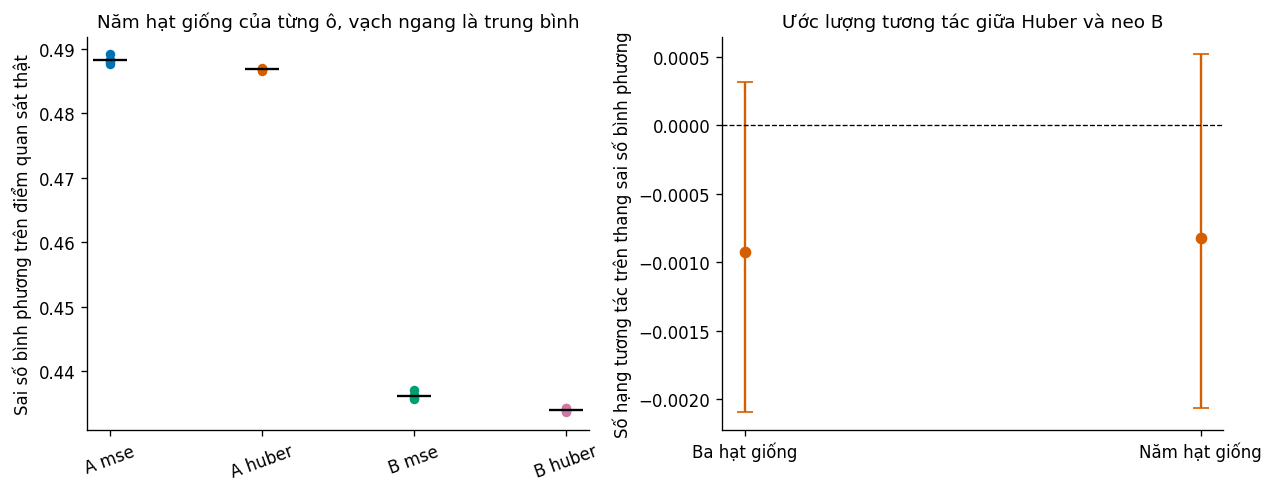

In [16]:
thu_tu = ["A_mse", "A_huber", "B_mse", "B_huber"]
fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.0))
for i, khoa in enumerate(thu_tu):
    gia_tri = TONG_HOP[khoa]["cac_gia_tri_mse"]
    ax[0].scatter([i] * len(gia_tri), gia_tri, color=PALETTE[i % len(PALETTE)], s=22)
    ax[0].scatter([i], [TONG_HOP[khoa]["mse_trung_binh"]], marker="_", s=400,
                  color="black")
ax[0].set_xticks(range(len(thu_tu)))
ax[0].set_xticklabels([t.replace("_", " ") for t in thu_tu], rotation=20)
ax[0].set_ylabel("Sai số bình phương trên điểm quan sát thật")
ax[0].set_title("Năm hạt giống của từng ô, vạch ngang là trung bình")

ten_cot = ["Ba hạt giống", "Năm hạt giống"]
gia = [TUONG_TAC["ba_hat_giong"]["tuong_tac_mse"], TUONG_TAC["nam_hat_giong"]["tuong_tac_mse"]]
ci = [TUONG_TAC["ba_hat_giong"]["tuong_tac_mse_ci"], TUONG_TAC["nam_hat_giong"]["tuong_tac_mse_ci"]]
duoi = [g - c[0] for g, c in zip(gia, ci)]
tren = [c[1] - g for g, c in zip(gia, ci)]
ax[1].errorbar(ten_cot, gia, yerr=[duoi, tren], fmt="o", color=PALETTE[1], capsize=5)
ax[1].axhline(0.0, color="black", linewidth=0.8, linestyle="--")
ax[1].set_ylabel("Số hạng tương tác trên thang sai số bình phương")
ax[1].set_title("Ước lượng tương tác giữa Huber và neo B")
luu_hinh(fig, "W3_17_luoi_nam_hat_giong.png")
plt.show()


## 8. Ghi kết quả

In [17]:
ket_qua = {
    "kiem_tra_luc": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG, "read_tag": READ_TAG, "n_seeds": N_SEEDS,
    "huber_delta": HUBER_DELTA, "n_boot": N_BOOT,
    "mse_persistence": MSE_PERSISTENCE, "mae_persistence": MAE_PERSISTENCE,
    "tong_hop": TONG_HOP, "tuong_tac": TUONG_TAC,
}
dich = RUN_DIR / "W3_luoi_nam_hat_giong.json"
dich.write_text(json.dumps(ket_qua, ensure_ascii=False, indent=2))
print("Đã ghi", dich)
ty_so = (TONG_HOP["B_mse"]["mse_do_lech_chuan"] /
         max(TONG_HOP["A_mse"]["mse_do_lech_chuan"], 1e-12))
print("Tỷ số độ lệch chuẩn giữa neo B và neo A:", round(float(ty_so), 4))


Đã ghi /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_17_luoi_nam_hat_giong/W3_luoi_nam_hat_giong.json
Tỷ số độ lệch chuẩn giữa neo B và neo A: 0.9664
